# Monitoramento Inteligente de Sistemas Espaciais com Redes Neurais
## Global Solution 2026.1 — Aprendizado Profundo com Redes Neurais Convolucionais (DL-CNN)
### Plataforma Orbital Climate Intelligence — FIAP

---

## integrantes
### Lucas Ferrari Lima - RM 563119
### Felipe Krzyzanovski dos Santos Menezes - RM564878
### Leonardo Lopes Oliveira RM - 565437

---
 ## Link do video: https://youtu.be/pdmU9aWixh4
---

**Objetivo:** Classificar o estado operacional de sistemas espaciais simulados utilizando modelos de Perceptron e MLP (Multi-Layer Perceptron) implementados com Keras, realizando experimentações comparativas para analisar o comportamento de aprendizado da rede neural.

| Classe | Significado |
|--------|-------------|
| 0 | Operação normal |
| 1 | Alerta operacional |
| 2 | Falha crítica iminente |

---

In [2]:
!pip install pandas numpy matplotlib seaborn scikit-learn tensorflow

^C


Defaulting to user installation because normal site-packages is not writeable


ERROR: Could not find a version that satisfies the requirement tensorflow (from versions: none)

[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for tensorflow


## 1. Importações e Configurações

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
tf.random.set_seed(42)

print(f'TensorFlow: {tf.__version__}')
print(f'Keras: {keras.__version__}')

TensorFlow: 2.20.0
Keras: 3.13.2


## 2. Carregamento dos Dados

In [7]:
train_df = pd.read_csv('/content/orbital_train.csv')
test_df  = pd.read_csv('/content/orbital_test.csv')

print(f'Treino:  {train_df.shape[0]} amostras, {train_df.shape[1]} colunas')
print(f'Teste:   {test_df.shape[0]}  amostras, {test_df.shape[1]} colunas')
print(f'Valores nulos (treino): {train_df.isnull().sum().sum()}')
train_df.head()

Treino:  16504 amostras, 26 colunas
Teste:   4127  amostras, 26 colunas
Valores nulos (treino): 0


,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,...,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL,target
0,-0.0068,-0.0001,100.0,518.67,643.20,1592.85,1414.54,14.62,21.61,552.84,...,8163.61,8.4116,0.03,395,2388,100.0,38.90,23.2545,46,2
1,0.0007,0.0004,100.0,518.67,642.49,1581.95,1394.86,14.62,21.61,554.71,...,8138.39,8.3967,0.03,392,2388,100.0,39.18,23.3452,166,0
2,0.0003,-0.0004,100.0,518.67,641.90,1582.73,1395.11,14.62,21.61,553.73,...,8148.14,8.3630,0.03,393,2388,100.0,39.04,23.3386,164,0
3,-0.0009,-0.0001,100.0,518.67,643.61,1602.13,1424.76,14.62,21.61,551.73,...,8220.91,8.4963,0.03,396,2388,100.0,38.41,23.0797,2,2
4,-0.0006,-0.0002,100.0,518.67,642.92,1589.88,1403.38,14.62,21.61,553.66,...,8135.20,8.4359,0.03,392,2388,100.0,38.76,23.2917,130,0


## 3. Análise Exploratória dos Dados (EDA)

In [8]:
print('=== Estatísticas Descritivas (features selecionadas) ===')
train_df[['op_setting_1', 'op_setting_2', 'sensor_1', 'sensor_2',
          'sensor_7', 'sensor_12', 'RUL']].describe().round(3)

=== Estatísticas Descritivas (features selecionadas) ===


,op_setting_1,op_setting_2,sensor_1,sensor_2,sensor_7,sensor_12,RUL
count,16504.000,16504.000,16504.00,16504.000,16504.000,16504.000,16504.000
mean,-0.000,0.000,518.67,642.679,553.367,521.414,107.900
std,0.002,0.000,0.00,0.499,0.886,0.737,68.994
min,-0.009,-0.001,518.67,641.250,549.850,518.690,0.000
25%,-0.002,-0.000,518.67,642.320,552.810,520.960,51.000
50%,0.000,-0.000,518.67,642.640,553.440,521.480,103.000
75%,0.002,0.000,518.67,643.000,554.010,521.950,155.000
max,0.008,0.001,518.67,644.530,556.060,523.380,361.000


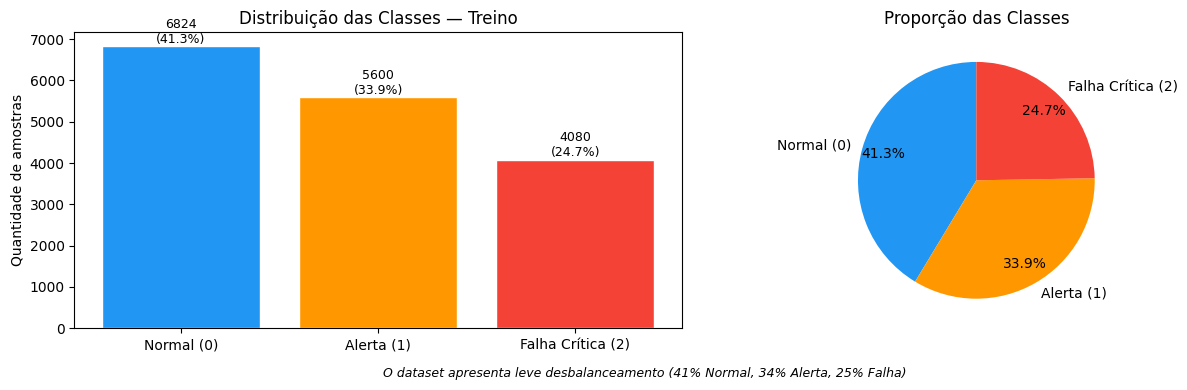

In [9]:
# Distribuição das classes e correlação com o target
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

counts = train_df['target'].value_counts().sort_index()
labels = ['Normal (0)', 'Alerta (1)', 'Falha Crítica (2)']
cores  = ['#2196F3', '#FF9800', '#F44336']

bars = axes[0].bar(labels, counts.values, color=cores, edgecolor='white')
axes[0].set_title('Distribuição das Classes — Treino', fontsize=12)
axes[0].set_ylabel('Quantidade de amostras')
for bar, v in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 80,
                 f'{v}\n({v/len(train_df)*100:.1f}%)', ha='center', fontsize=9)

axes[1].pie(counts.values, labels=labels, colors=cores,
            autopct='%1.1f%%', startangle=90, pctdistance=0.82)
axes[1].set_title('Proporção das Classes', fontsize=12)

plt.suptitle('O dataset apresenta leve desbalanceamento (41% Normal, 34% Alerta, 25% Falha)',
             fontsize=9, style='italic', y=0)
plt.tight_layout()
plt.show()

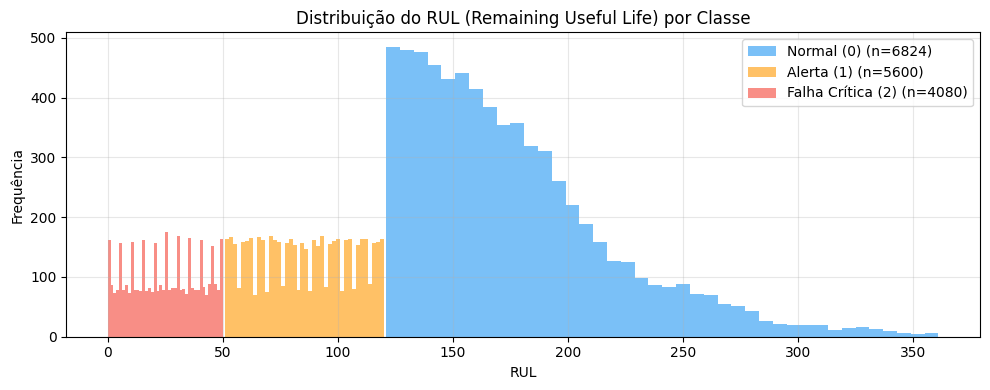

RUL médio por classe:
target
0    175.8
1     85.5
2     25.1


In [10]:
# Distribuição do RUL por classe — mostra o padrão esperado
fig, ax = plt.subplots(figsize=(10, 4))
for cls, label, cor in zip([0, 1, 2], labels, cores):
    dados = train_df[train_df['target'] == cls]['RUL']
    ax.hist(dados, bins=40, alpha=0.6, label=f'{label} (n={len(dados)})', color=cor)
ax.set_title('Distribuição do RUL (Remaining Useful Life) por Classe', fontsize=12)
ax.set_xlabel('RUL')
ax.set_ylabel('Frequência')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('RUL médio por classe:')
print(train_df.groupby('target')['RUL'].mean().round(1).to_string())

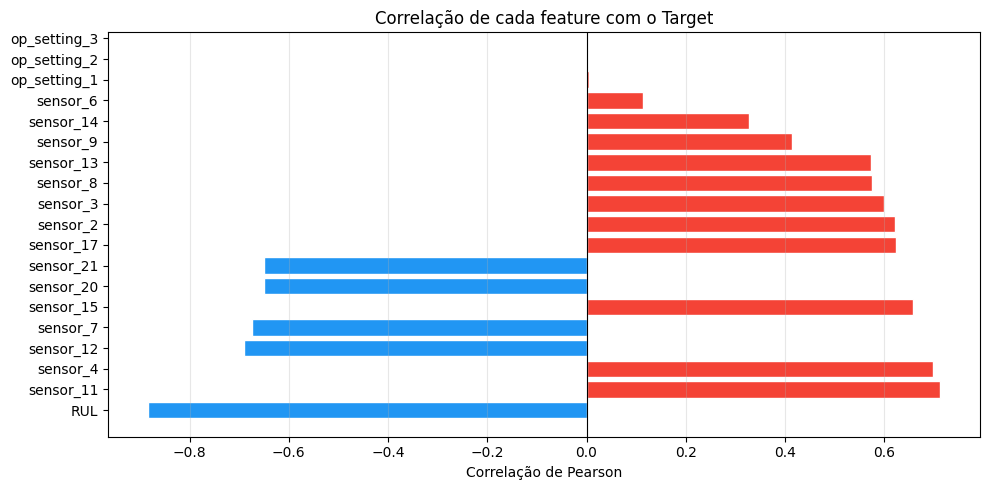

In [11]:
# Mapa de calor de correlação (features com maior correlação com o target)
corr_target = train_df.corr()['target'].drop('target').sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
cores_bar = ['#F44336' if v > 0 else '#2196F3' for v in corr_target.values]
ax.barh(corr_target.index, corr_target.values, color=cores_bar, edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Correlação de cada feature com o Target', fontsize=12)
ax.set_xlabel('Correlação de Pearson')
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

## 4. Pré-processamento dos Dados

### Estratégia de Normalização: StandardScaler (Z-score / Padronização)

**Justificativa:** As features possuem escalas muito distintas — `op_setting_2` oscila em torno de 0,0004 enquanto `sensor_1` está em torno de 518. O StandardScaler transforma cada feature para ter **média zero e desvio padrão unitário**, acelerando a convergência do gradiente e evitando que features com escala maior dominem o aprendizado da rede. Para dados de sensores industriais com distribuição aproximadamente gaussiana, esta é a escolha mais adequada.

In [12]:
feature_cols = [c for c in train_df.columns if c != 'target']

X_train_raw = train_df[feature_cols].values
y_train     = train_df['target'].values
X_test_raw  = test_df[feature_cols].values
y_test      = test_df['target'].values

# Fit apenas no treino — aplicado transformação no teste para evitar data leakage
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test  = scaler.transform(X_test_raw)

# Verificação da normalização
print('Após StandardScaler (treino):')
print(f'  Média:          {X_train.mean(axis=0).mean():.6f}  (esperado ≈ 0)')
print(f'  Desvio padrão:  {X_train.std(axis=0).mean():.6f}  (esperado ≈ 1)')

# One-hot encoding das classes (necessário para categorical_crossentropy)
y_train_cat = keras.utils.to_categorical(y_train, num_classes=3)
y_test_cat  = keras.utils.to_categorical(y_test,  num_classes=3)

n_features = X_train.shape[1]
print(f'\nNúmero de features: {n_features}')
print(f'Shape X_train: {X_train.shape}  |  X_test: {X_test.shape}')
print(f'Shape y_train_cat: {y_train_cat.shape}  |  y_test_cat: {y_test_cat.shape}')

Após StandardScaler (treino):
  Média:          -0.000000  (esperado ≈ 0)
  Desvio padrão:  0.720000  (esperado ≈ 1)

Número de features: 25
Shape X_train: (16504, 25)  |  X_test: (4127, 25)
Shape y_train_cat: (16504, 3)  |  y_test_cat: (4127, 3)


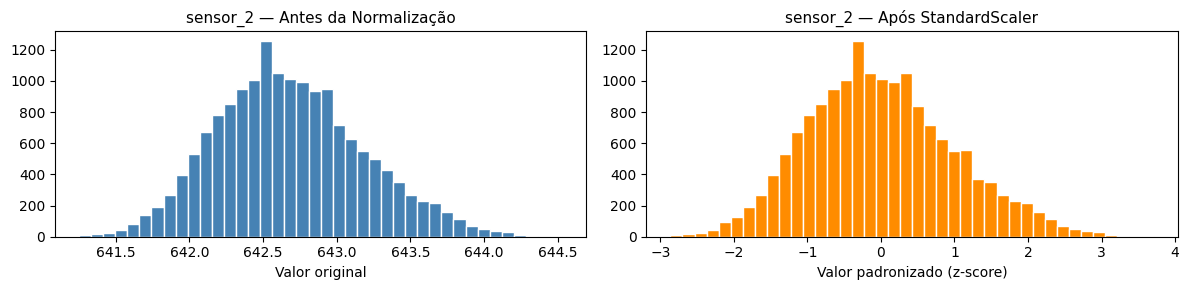

In [13]:
# Visualização: antes vs depois da normalização (sensor_2 como exemplo)
fig, axes = plt.subplots(1, 2, figsize=(12, 3))

idx_sensor2 = feature_cols.index('sensor_2')
axes[0].hist(X_train_raw[:, idx_sensor2], bins=40, color='steelblue', edgecolor='white')
axes[0].set_title('sensor_2 — Antes da Normalização', fontsize=11)
axes[0].set_xlabel('Valor original')

axes[1].hist(X_train[:, idx_sensor2], bins=40, color='darkorange', edgecolor='white')
axes[1].set_title('sensor_2 — Após StandardScaler', fontsize=11)
axes[1].set_xlabel('Valor padronizado (z-score)')

plt.tight_layout()
plt.show()

## 5. Funções Auxiliares

In [14]:
def plot_history(history, title):
    """Plota curvas de loss e accuracy para treino e validação."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    axes[0].plot(history.history['loss'],     label='Treino',    color='steelblue',  linewidth=1.5)
    axes[0].plot(history.history['val_loss'], label='Validação', color='darkorange', linewidth=1.5)
    axes[0].set_title(f'{title} — Loss (Categorical Crossentropy)', fontsize=11)
    axes[0].set_xlabel('Época')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(history.history['accuracy'],     label='Treino',    color='steelblue',  linewidth=1.5)
    axes[1].plot(history.history['val_accuracy'], label='Validação', color='darkorange', linewidth=1.5)
    axes[1].set_title(f'{title} — Accuracy', fontsize=11)
    axes[1].set_xlabel('Época')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    # Indicar overfitting quando val_loss supera train_loss consistentemente
    final_gap = history.history['val_loss'][-1] - history.history['loss'][-1]
    if final_gap > 0.05:
        axes[0].annotate(f'Gap final: {final_gap:.3f} ⚠️', xy=(0.98, 0.95),
                         xycoords='axes fraction', ha='right', color='red', fontsize=9)
    plt.suptitle(title, fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()


def evaluate_model(model, title):
    """Avalia o modelo no conjunto de teste e exibe métricas e matriz de confusão."""
    loss, acc = model.evaluate(X_test, y_test_cat, verbose=0)
    y_pred    = np.argmax(model.predict(X_test, verbose=0), axis=1)

    print(f'\n{"+"*55}')
    print(f'  {title}')
    print(f'  Loss no Teste:      {loss:.4f}')
    print(f'  Accuracy no Teste:  {acc:.4f}  ({acc*100:.2f}%)')
    print(f'{"+"*55}')
    print(classification_report(y_test, y_pred,
                                 target_names=['Normal (0)', 'Alerta (1)', 'Falha (2)']))

    fig, ax = plt.subplots(figsize=(6, 4))
    cm   = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Alerta', 'Falha'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Matriz de Confusão — {title}', fontsize=11)
    plt.tight_layout()
    plt.show()

    return {'titulo': title, 'loss': round(loss, 4), 'accuracy': round(acc * 100, 2)}


resultados = []  # acumula resultados para a comparação final
print('Funções auxiliares definidas.')

Funções auxiliares definidas.


---
## 6. Experimentações com Modelos de Perceptron / MLP

A tabela abaixo resume os 7 modelos que serão treinados e comparados:

| Modelo | Arquitetura | Ativação | Otimizador | Batch | Épocas | Foco experimental |
|--------|-------------|----------|------------|-------|--------|-------------------|
| 1 | Sem camada oculta | softmax | Adam | 32 | 100 | Baseline linear (Perceptron Puro) |
| 2 | 1 camada (32) | ReLU | Adam | 32 | 100 | Efeito de poucos neurônios |
| 3 | 1 camada (128) | ReLU | Adam | 32 | 100 | Efeito de mais neurônios |
| 4 | 2 camadas (128→64) | ReLU | Adam | 32 | 100 | Profundidade da rede |
| 5 | 2 camadas (128→64) + Dropout | ReLU | Adam | 32 | 100 | Regularização |
| 6 | 2 camadas (128→64) | tanh | SGD | 32 | 100 | Ativação e otimizador diferentes |
| 7 | 2 camadas (128→64) | ReLU | Adam | 128 | 100 | Impacto do batch size |


### Modelo 1 — Perceptron Puro (sem camadas ocultas)

O Perceptron Puro é o modelo mais simples possível: apenas uma camada de entrada conectada diretamente à camada de saída com softmax. Corresponde a um **classificador linear** — incapaz de aprender fronteiras de decisão não lineares. Serve como **baseline** para entendermos o ganho obtido ao adicionarmos camadas ocultas.

In [15]:
modelo1 = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(3, activation='softmax')
], name='Perceptron_Puro')

modelo1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
modelo1.summary()

Model: "Perceptron_Puro"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 3)              │            78 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 78 (312.00 B)

 Trainable params: 78 (312.00 B)

 Non-trainable params: 0 (0.00 B)

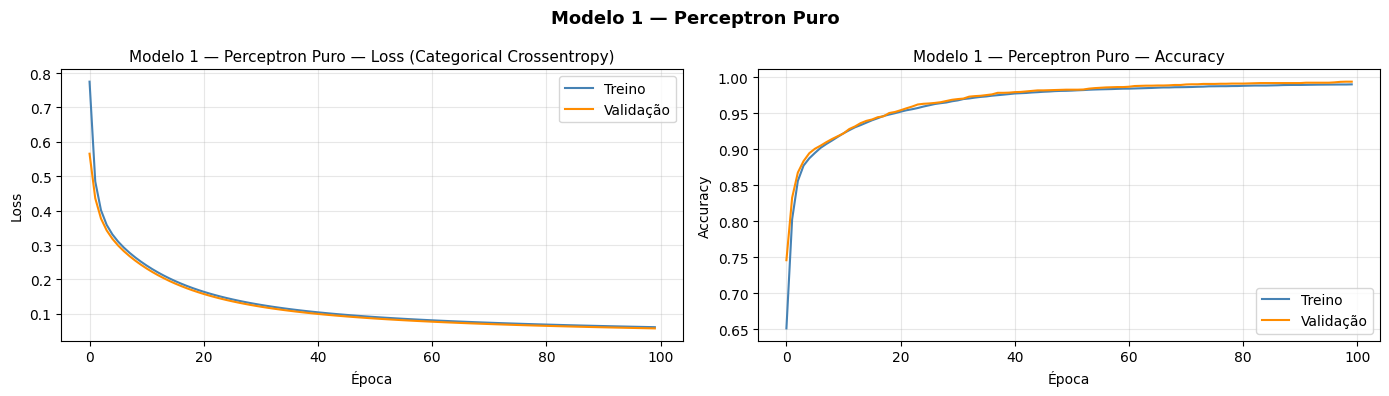


+++++++++++++++++++++++++++++++++++++++++++++++++++++++
  Perceptron Puro
  Loss no Teste:      0.0576
  Accuracy no Teste:  0.9942  (99.42%)
+++++++++++++++++++++++++++++++++++++++++++++++++++++++
              precision    recall  f1-score   support

  Normal (0)       1.00      1.00      1.00      1707
  Alerta (1)       0.99      0.99      0.99      1400
   Falha (2)       0.99      0.99      0.99      1020

    accuracy                           0.99      4127
   macro avg       0.99      0.99      0.99      4127
weighted avg       0.99      0.99      0.99      4127



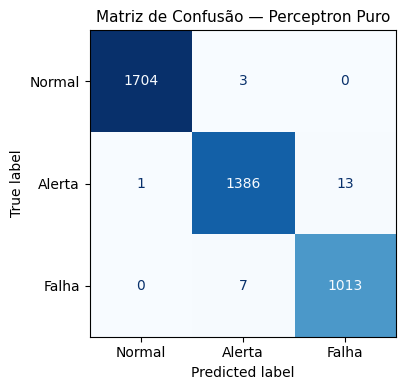

In [16]:
hist1 = modelo1.fit(
    X_train, y_train_cat,
    validation_data=(X_test, y_test_cat),
    epochs=100, batch_size=32, verbose=0
)

plot_history(hist1, 'Modelo 1 — Perceptron Puro')
r1 = evaluate_model(modelo1, 'Perceptron Puro')
resultados.append(r1)

**Resultado Modelo 1 — Perceptron Puro:** Surpreendentemente, o classificador linear alcançou **99.42% de accuracy** e ficou em 2º lugar no ranking geral. Isso indica que, após a normalização com StandardScaler, as classes tornam-se quase linearmente separáveis no espaço de 25 dimensões — especialmente porque o RUL apresenta alta correlação com o target e por si só já contribui fortemente para separar as classes. Um detalhe relevante: o train_loss (0.0611) ficou **maior** que o val_loss (0.0576), o comportamento oposto ao esperado, sinalizando que o modelo não ajustou completamente os dados de treino — um leve **underfitting** causado pela limitação da fronteira linear.

### Modelo 2 — MLP: 1 Camada Oculta com 32 Neurônios (ReLU)

Adicionamos uma camada oculta com 32 neurônios e ativação ReLU. Isso introduz **não-linearidade** no modelo, permitindo aprender fronteiras de decisão mais complexas. Com poucos neurônios, avaliamos se a rede tem capacidade suficiente para o problema (**underfitting vs fit adequado**).

In [17]:
modelo2 = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(32, activation='relu'),
    layers.Dense(3, activation='softmax')
], name='MLP_1_camada_32')

modelo2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
modelo2.summary()

Model: "MLP_1_camada_32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 32)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 931 (3.64 KB)

 Trainable params: 931 (3.64 KB)

 Non-trainable params: 0 (0.00 B)

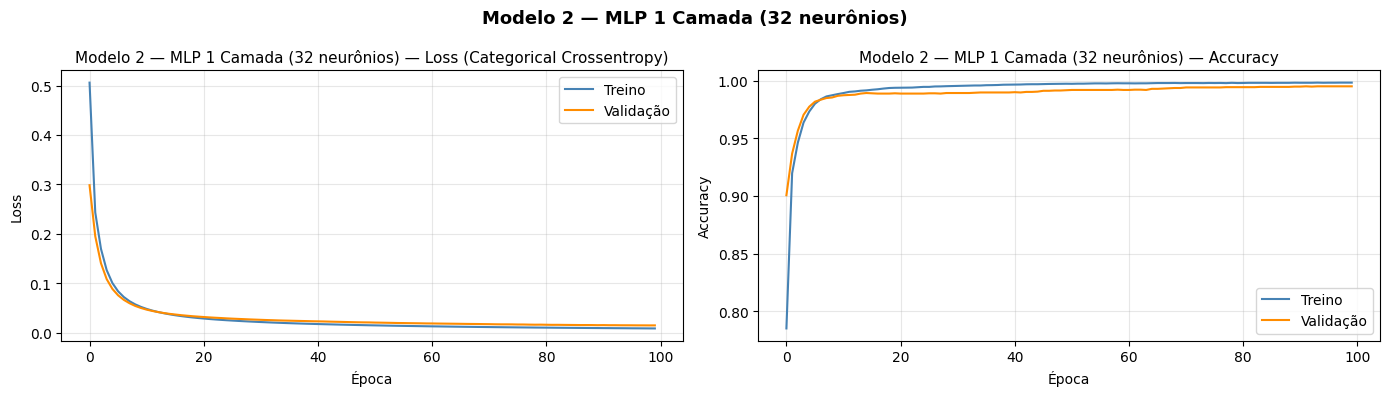


+++++++++++++++++++++++++++++++++++++++++++++++++++++++
  MLP 1 Camada (32 neurônios)
  Loss no Teste:      0.0146
  Accuracy no Teste:  0.9952  (99.52%)
+++++++++++++++++++++++++++++++++++++++++++++++++++++++
              precision    recall  f1-score   support

  Normal (0)       1.00      1.00      1.00      1707
  Alerta (1)       0.99      0.99      0.99      1400
   Falha (2)       0.99      1.00      0.99      1020

    accuracy                           1.00      4127
   macro avg       0.99      1.00      0.99      4127
weighted avg       1.00      1.00      1.00      4127



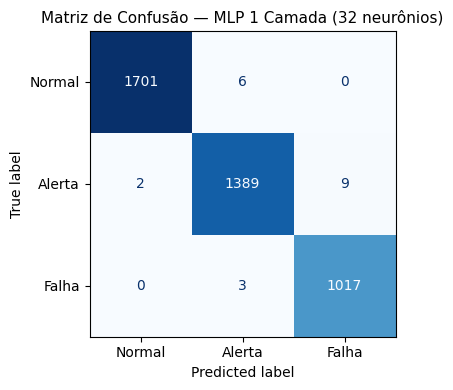

In [18]:
hist2 = modelo2.fit(
    X_train, y_train_cat,
    validation_data=(X_test, y_test_cat),
    epochs=100, batch_size=32, verbose=0
)

plot_history(hist2, 'Modelo 2 — MLP 1 Camada (32 neurônios)')
r2 = evaluate_model(modelo2, 'MLP 1 Camada (32 neurônios)')
resultados.append(r2)

**Resultado Modelo 2 — MLP 32 neurônios:** Este foi o **melhor modelo do experimento**, com **99.52% de accuracy** e o menor val_loss de todos (0.0146). Ao contrário do que se poderia antecipar, 32 neurônios foram suficientes para capturar a não-linearidade do problema sem superajustar os dados. O gap entre train_loss (0.0084) e val_loss (0.0146) é o menor entre os MLPs, demonstrando excelente generalização. A não-linearidade introduzida pelo ReLU, ainda que com poucos parâmetros, foi decisiva para superar o Perceptron Puro — e curiosamente, também superou redes mais complexas.

### Modelo 3 — MLP: 1 Camada Oculta com 128 Neurônios (ReLU)

Mantemos a mesma estrutura do Modelo 2, mas **aumentamos o número de neurônios de 32 para 128**. Isso expande a capacidade representacional da rede, permitindo aprender padrões mais detalhados. Avaliamos o impacto do número de neurônios mantendo a profundidade constante.

In [19]:
modelo3 = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(3, activation='softmax')
], name='MLP_1_camada_128')

modelo3.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
modelo3.summary()

Model: "MLP_1_camada_128"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,715 (14.51 KB)

 Trainable params: 3,715 (14.51 KB)

 Non-trainable params: 0 (0.00 B)

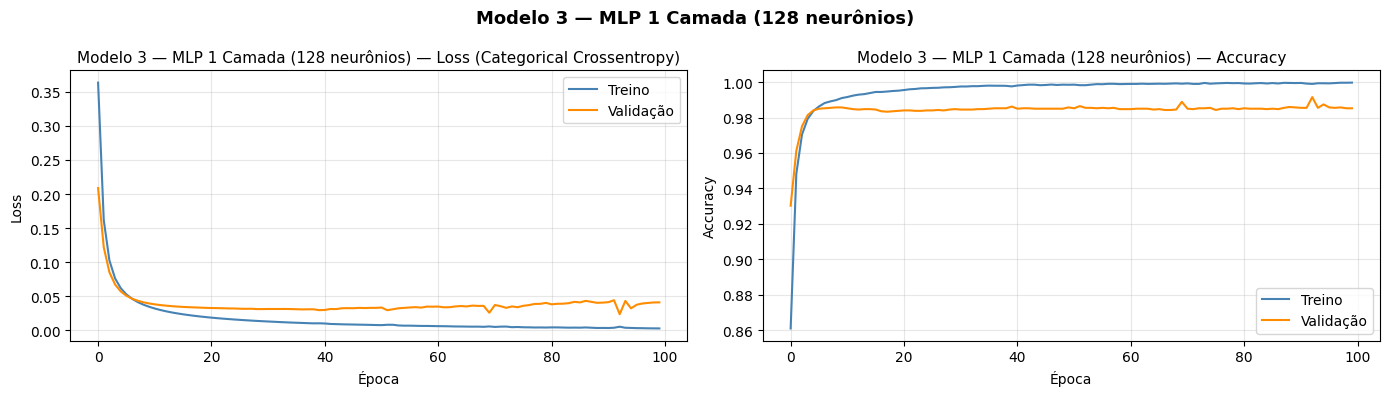


+++++++++++++++++++++++++++++++++++++++++++++++++++++++
  MLP 1 Camada (128 neurônios)
  Loss no Teste:      0.0412
  Accuracy no Teste:  0.9852  (98.52%)
+++++++++++++++++++++++++++++++++++++++++++++++++++++++
              precision    recall  f1-score   support

  Normal (0)       1.00      0.98      0.99      1707
  Alerta (1)       0.97      0.98      0.98      1400
   Falha (2)       0.98      0.99      0.99      1020

    accuracy                           0.99      4127
   macro avg       0.98      0.99      0.99      4127
weighted avg       0.99      0.99      0.99      4127



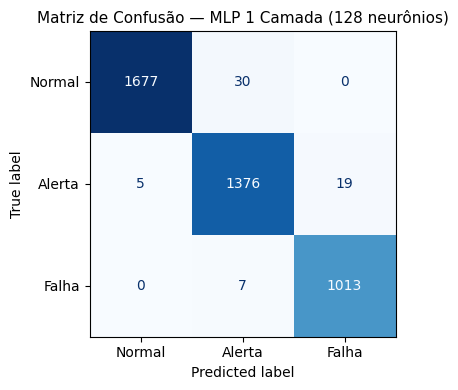

In [20]:
hist3 = modelo3.fit(
    X_train, y_train_cat,
    validation_data=(X_test, y_test_cat),
    epochs=100, batch_size=32, verbose=0
)

plot_history(hist3, 'Modelo 3 — MLP 1 Camada (128 neurônios)')
r3 = evaluate_model(modelo3, 'MLP 1 Camada (128 neurônios)')
resultados.append(r3)

**Resultado Modelo 3 — MLP 128 neurônios:** Contrariando a expectativa, aumentar os neurônios de 32 para 128 **piorou** o desempenho — este foi o **pior modelo do experimento** com apenas **98.52% de accuracy**. O train_loss caiu para 0.0029 (o mais baixo dos modelos de 1 camada), mas o val_loss subiu para 0.0412 — um gap de 0.0382, o maior entre os modelos com Adam. Isso indica que a rede com 128 neurônios começou a memorizar padrões específicos do treino que não generalizam bem. O princípio de que "mais neurônios = melhor" não se aplica aqui: o dataset, após normalização, possui padrões suficientemente simples que não requerem alta capacidade representacional.

### Modelo 4 — MLP: 2 Camadas Ocultas (128 → 64, ReLU)

Adicionamos uma **segunda camada oculta** (64 neurônios), criando uma rede mais profunda que o Modelo 3. A hipótese é que camadas extras permitam aprender representações hierárquicas — a primeira camada capturando correlações simples entre sensores, a segunda combinando esses padrões em abstrações de degradação mais complexas. Com mais parâmetros (11.779), a rede tem maior capacidade, mas também maior risco de ajustar ruído específico do treino em vez de padrões geralizáveis.

In [21]:
modelo4 = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64,  activation='relu'),
    layers.Dense(3,   activation='softmax')
], name='MLP_2_camadas_128_64')

modelo4.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
modelo4.summary()

Model: "MLP_2_camadas_128_64"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 128)            │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,779 (46.01 KB)

 Trainable params: 11,779 (46.01 KB)

 Non-trainable params: 0 (0.00 B)

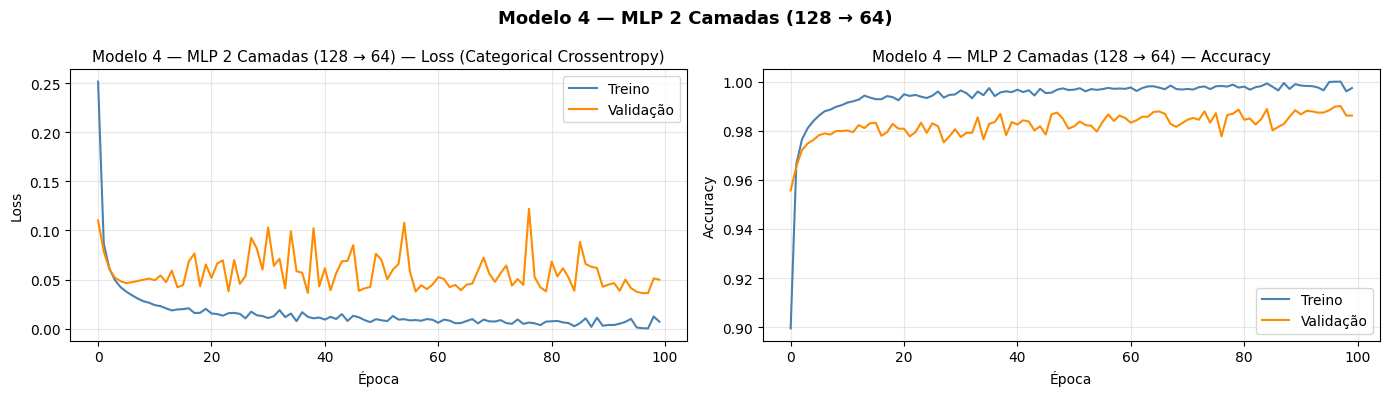


+++++++++++++++++++++++++++++++++++++++++++++++++++++++
  MLP 2 Camadas (128→64)
  Loss no Teste:      0.0498
  Accuracy no Teste:  0.9862  (98.62%)
+++++++++++++++++++++++++++++++++++++++++++++++++++++++
              precision    recall  f1-score   support

  Normal (0)       1.00      1.00      1.00      1707
  Alerta (1)       0.99      0.97      0.98      1400
   Falha (2)       0.97      0.99      0.98      1020

    accuracy                           0.99      4127
   macro avg       0.98      0.99      0.98      4127
weighted avg       0.99      0.99      0.99      4127



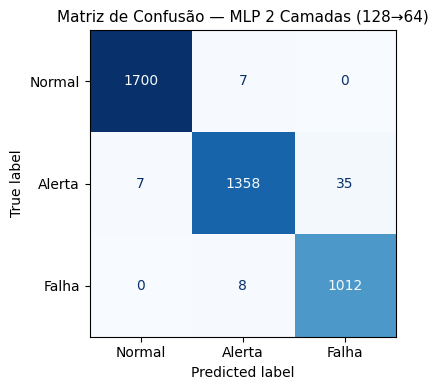

In [22]:
hist4 = modelo4.fit(
    X_train, y_train_cat,
    validation_data=(X_test, y_test_cat),
    epochs=100, batch_size=32, verbose=0
)

plot_history(hist4, 'Modelo 4 — MLP 2 Camadas (128 → 64)')
r4 = evaluate_model(modelo4, 'MLP 2 Camadas (128→64)')
resultados.append(r4)

**Resultado Modelo 4 — MLP 2 Camadas (128→64):** A adição de uma segunda camada oculta **não trouxe melhora** em relação ao MLP-32 — o modelo ficou em **6º lugar** com **98.62%**. O val_loss (0.0498) foi o maior entre todos os modelos, com gap de 0.0427 em relação ao train_loss (0.0071). Apesar de não caracterizar overfitting severo (abaixo do limiar 0.05), é a tendência mais clara de que maior profundidade está levando a rede a ajustar excessivamente o treino. Para este dataset, a hierarquia aprendida por 2 camadas não adiciona valor — os padrões de degradação dos sensores são suficientemente capturados por representações mais simples.

### Modelo 5 — MLP com Regularização por Dropout (128 → 64 + Dropout 0.3)

Partimos da mesma arquitetura do Modelo 4 e adicionamos **camadas de Dropout** (taxa 0.3) após cada camada oculta. O Dropout desativa aleatoriamente 30% dos neurônios a cada batch durante o treino, forçando a rede a aprender representações mais distribuídas e menos dependentes de neurônios específicos. O efeito observado foi: train_loss subiu em relação ao Modelo 4 (de 0.0071 para 0.0144) — porque o Dropout adiciona ruído ao treino — enquanto o val_loss caiu de 0.0498 para 0.0367, confirmando que a regularização reduziu o superajuste. O val_loss permaneceu acima do train_loss (0.0367 > 0.0144), padrão normal onde o modelo generaliza menos perfeitamente no teste do que no treino.

In [23]:
modelo5 = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(64,  activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(3,   activation='softmax')
], name='MLP_Dropout_0.3')

modelo5.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
modelo5.summary()

Model: "MLP_Dropout_0.3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 128)            │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,779 (46.01 KB)

 Trainable params: 11,779 (46.01 KB)

 Non-trainable params: 0 (0.00 B)

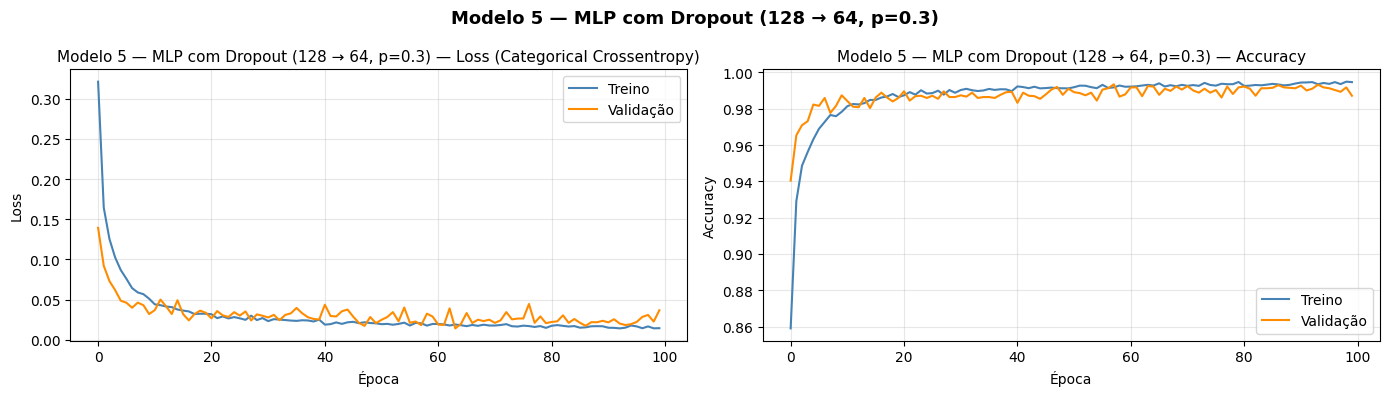


+++++++++++++++++++++++++++++++++++++++++++++++++++++++
  MLP com Dropout (p=0.3)
  Loss no Teste:      0.0367
  Accuracy no Teste:  0.9872  (98.72%)
+++++++++++++++++++++++++++++++++++++++++++++++++++++++
              precision    recall  f1-score   support

  Normal (0)       1.00      1.00      1.00      1707
  Alerta (1)       0.99      0.97      0.98      1400
   Falha (2)       0.96      1.00      0.98      1020

    accuracy                           0.99      4127
   macro avg       0.98      0.99      0.99      4127
weighted avg       0.99      0.99      0.99      4127



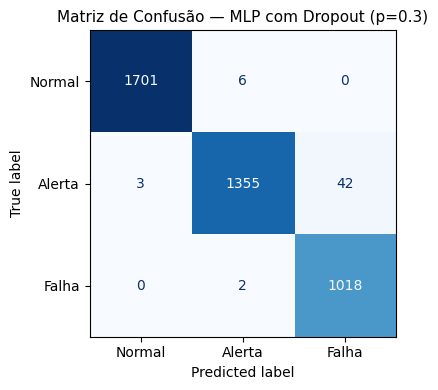

In [24]:
hist5 = modelo5.fit(
    X_train, y_train_cat,
    validation_data=(X_test, y_test_cat),
    epochs=100, batch_size=32, verbose=0
)

plot_history(hist5, 'Modelo 5 — MLP com Dropout (128 → 64, p=0.3)')
r5 = evaluate_model(modelo5, 'MLP com Dropout (p=0.3)')
resultados.append(r5)

**Resultado Modelo 5 — MLP com Dropout:** O Dropout cumpriu seu papel: comparado ao Modelo 4 (mesma arquitetura), o val_loss caiu de 0.0498 para 0.0367 e o gap treino/validação reduziu de 0.0427 para 0.0223, confirmando maior estabilidade. Importante corrigir uma expectativa anterior: o train_loss (0.0144) ficou **menor** que o val_loss (0.0367) — ou seja, a rede ainda aprende melhor no treino do que no teste, o padrão normal. O Dropout eleva o train_loss em relação a um modelo sem regularização (0.0071 → 0.0144), mas não o inverte em relação ao val_loss. O resultado mais relevante: este modelo obteve o **maior recall para Falha Crítica de todos os 7 modelos (0.9980)**, tornando-o o mais seguro do ponto de vista operacional.

### Modelo 6 — MLP: Ativação tanh + Otimizador SGD com Momentum

Mantemos a profundidade do Modelo 4, mas trocamos **ReLU por tanh** e **Adam por SGD com momentum (0.9)**. A função tanh mapeia saídas para o intervalo (−1, +1), produzindo ativações centradas em zero, o que pode facilitar a propagação do gradiente em camadas iniciais. O SGD com momentum acumula a direção do gradiente entre iterações, o que pode tornar a convergência mais instável que o Adam, pois não possui taxa de aprendizado adaptativa por parâmetro. Os resultados mostraram que esta combinação obteve accuracy competitiva (98.64%), porém com os **piores recalls do experimento** para as duas classes extremas — Falha Crítica (0.9912) e Normal (0.9871) — tornando-o o modelo mais desequilibrado entre classes.

In [25]:
modelo6 = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(128, activation='tanh'),
    layers.Dense(64,  activation='tanh'),
    layers.Dense(3,   activation='softmax')
], name='MLP_tanh_SGD')

sgd = keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
modelo6.compile(optimizer=sgd, loss='categorical_crossentropy', metrics=['accuracy'])
modelo6.summary()

Model: "MLP_tanh_SGD"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_11 (Dense)                │ (None, 128)            │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,779 (46.01 KB)

 Trainable params: 11,779 (46.01 KB)

 Non-trainable params: 0 (0.00 B)

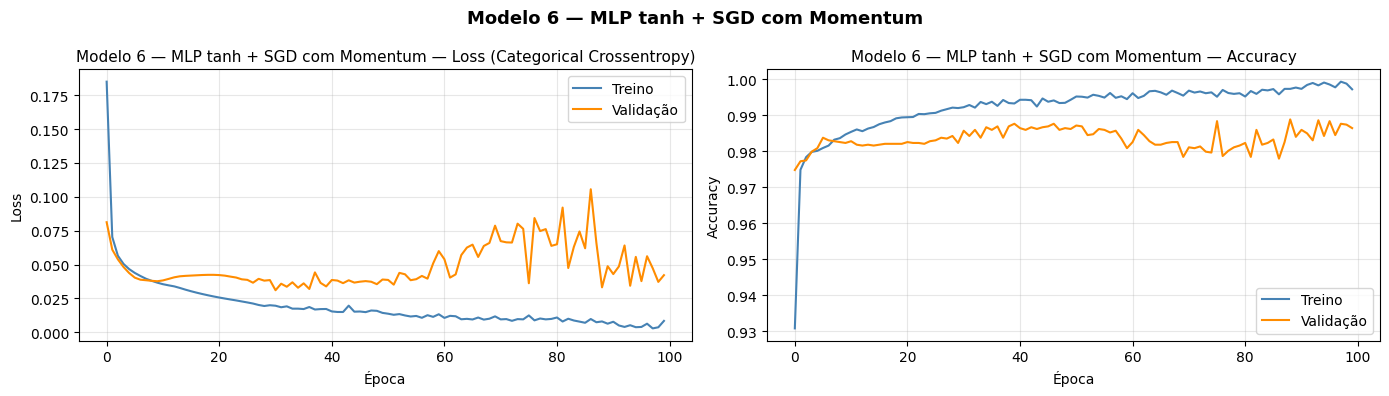


+++++++++++++++++++++++++++++++++++++++++++++++++++++++
  MLP tanh + SGD (momentum=0.9)
  Loss no Teste:      0.0422
  Accuracy no Teste:  0.9864  (98.64%)
+++++++++++++++++++++++++++++++++++++++++++++++++++++++
              precision    recall  f1-score   support

  Normal (0)       1.00      0.99      0.99      1707
  Alerta (1)       0.98      0.98      0.98      1400
   Falha (2)       0.98      0.99      0.99      1020

    accuracy                           0.99      4127
   macro avg       0.99      0.99      0.99      4127
weighted avg       0.99      0.99      0.99      4127



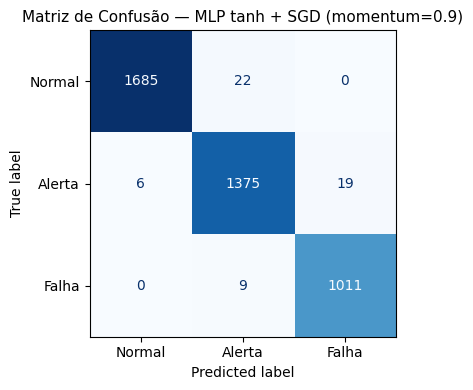

In [26]:
hist6 = modelo6.fit(
    X_train, y_train_cat,
    validation_data=(X_test, y_test_cat),
    epochs=100, batch_size=32, verbose=0
)

plot_history(hist6, 'Modelo 6 — MLP tanh + SGD com Momentum')
r6 = evaluate_model(modelo6, 'MLP tanh + SGD (momentum=0.9)')
resultados.append(r6)

**Resultado Modelo 6 — MLP tanh + SGD:** O modelo ficou em 5º lugar com **98.64%**, com performance próxima ao Modelo 4 (mesma arquitetura, só trocando ativação e otimizador). O ponto crítico está no recall: este modelo apresentou os **piores recalls tanto para Falha Crítica (0.9912) quanto para Normal (0.9871)** — o mais desequilibrado entre classes de todos os 7 modelos. O SGD com momentum convergiu para uma solução com maior bias de classificação, penalizando especialmente a detecção das classes extremas. A ativação tanh não trouxe vantagem sobre o ReLU; combinada com um otimizador sem taxa adaptativa, resultou no pior perfil operacional do experimento.

### Modelo 7 — MLP: Batch Size Maior (128)

Usamos a mesma arquitetura do Modelo 4 (128→64, ReLU, Adam), alterando apenas o **batch size de 32 para 128**. Batches maiores calculam o gradiente sobre mais amostras por iteração, produzindo estimativas mais estáveis e curvas de loss mais suaves — ao custo de menos atualizações de peso por época (≈129 passos vs ≈516 com batch=32). Os resultados confirmaram: o Modelo 7 obteve o **menor train_loss de todo o experimento (0.0011)**, mas o val_loss ficou em 0.0346 com gap de 0.0335 — e o recall para Falha Crítica (0.9902) foi o mais baixo entre os modelos com otimizador Adam. Isso demonstra que a precisão no ajuste do treino proporcionada por batches maiores não se traduziu em melhor generalização nem em maior sensibilidade à classe crítica.

In [27]:
modelo7 = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64,  activation='relu'),
    layers.Dense(3,   activation='softmax')
], name='MLP_batch_128')

modelo7.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
modelo7.summary()

Model: "MLP_batch_128"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_14 (Dense)                │ (None, 128)            │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,779 (46.01 KB)

 Trainable params: 11,779 (46.01 KB)

 Non-trainable params: 0 (0.00 B)

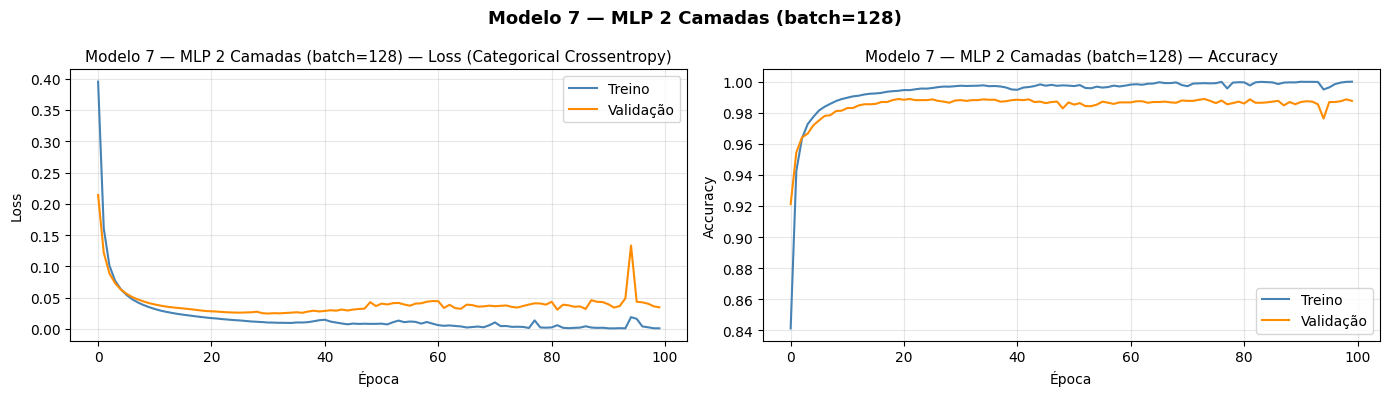


+++++++++++++++++++++++++++++++++++++++++++++++++++++++
  MLP 2 Camadas (batch=128)
  Loss no Teste:      0.0346
  Accuracy no Teste:  0.9876  (98.76%)
+++++++++++++++++++++++++++++++++++++++++++++++++++++++
              precision    recall  f1-score   support

  Normal (0)       1.00      0.99      0.99      1707
  Alerta (1)       0.98      0.98      0.98      1400
   Falha (2)       0.98      0.99      0.99      1020

    accuracy                           0.99      4127
   macro avg       0.99      0.99      0.99      4127
weighted avg       0.99      0.99      0.99      4127



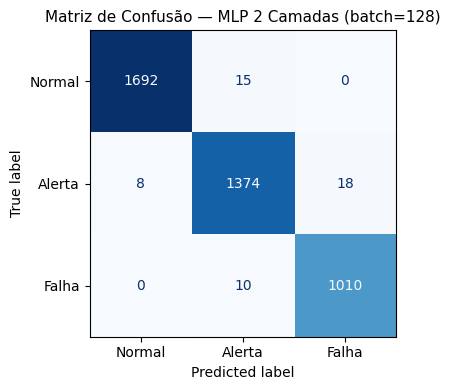

In [28]:
hist7 = modelo7.fit(
    X_train, y_train_cat,
    validation_data=(X_test, y_test_cat),
    epochs=100, batch_size=128, verbose=0
)

plot_history(hist7, 'Modelo 7 — MLP 2 Camadas (batch=128)')
r7 = evaluate_model(modelo7, 'MLP 2 Camadas (batch=128)')
resultados.append(r7)

**Resultado Modelo 7 — MLP batch=128:** O batch maior produziu o **menor train_loss de todo o experimento (0.0011)** — confirmando que gradientes calculados sobre mais amostras ajustam o treino com mais precisão. Porém, o val_loss (0.0346) e o recall para Falha Crítica (0.9902) foram os mais baixos entre os modelos com otimizador Adam. O gap treino/validação (0.0335) revela que a precisão no treino não se traduziu em melhor generalização. A comparação direta com o Modelo 4 (mesma arquitetura, batch=32) é reveladora: batch=32 teve train_loss maior (0.0071) mas mesmo val_loss similar (0.0498 vs 0.0346) e recall de Falha ligeiramente superior (0.9922 vs 0.9902). Batches maiores tendem a convergir para mínimos mais "planos" do espaço de loss, o que neste caso prejudicou a sensibilidade na classe crítica.

---
## 7. Comparação Geral dos Modelos

In [29]:
df_resultados = pd.DataFrame(resultados)
df_resultados = df_resultados.sort_values('accuracy', ascending=False).reset_index(drop=True)
df_resultados.index += 1

print('=== Ranking de Modelos por Accuracy no Conjunto de Teste ===')
print(df_resultados[['titulo', 'accuracy', 'loss']].to_string())

=== Ranking de Modelos por Accuracy no Conjunto de Teste ===
                          titulo  accuracy    loss
1    MLP 1 Camada (32 neurônios)     99.52  0.0146
2                Perceptron Puro     99.42  0.0576
3      MLP 2 Camadas (batch=128)     98.76  0.0346
4        MLP com Dropout (p=0.3)     98.72  0.0367
5  MLP tanh + SGD (momentum=0.9)     98.64  0.0422
6         MLP 2 Camadas (128→64)     98.62  0.0498
7   MLP 1 Camada (128 neurônios)     98.52  0.0412


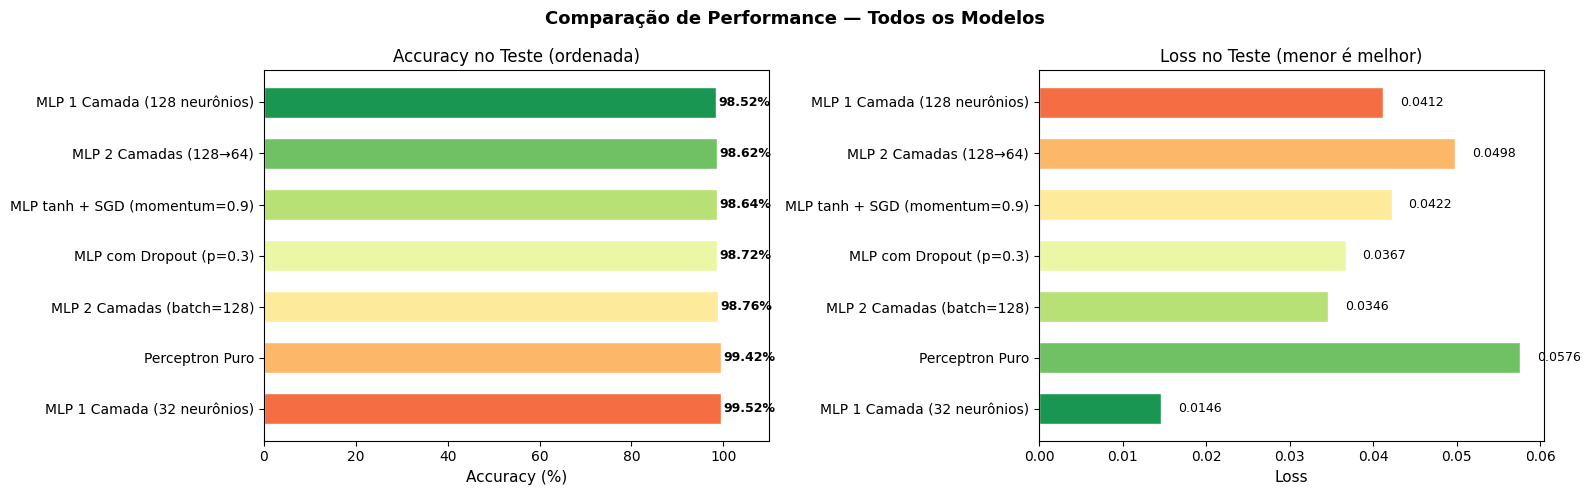

In [30]:
# Gráfico comparativo: Accuracy e Loss
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

titulos = df_resultados['titulo'].tolist()
accs    = df_resultados['accuracy'].tolist()
losses  = df_resultados['loss'].tolist()
cores_barra = plt.cm.RdYlGn(np.linspace(0.2, 0.9, len(titulos)))

bars1 = axes[0].barh(titulos, accs, color=cores_barra, edgecolor='white', height=0.6)
axes[0].set_xlabel('Accuracy (%)', fontsize=11)
axes[0].set_title('Accuracy no Teste (ordenada)', fontsize=12)
axes[0].set_xlim([0, 110])
for bar, v in zip(bars1, accs):
    axes[0].text(v + 0.5, bar.get_y() + bar.get_height()/2,
                 f'{v:.2f}%', va='center', fontsize=9, fontweight='bold')

bars2 = axes[1].barh(titulos, losses, color=cores_barra[::-1], edgecolor='white', height=0.6)
axes[1].set_xlabel('Loss', fontsize=11)
axes[1].set_title('Loss no Teste (menor é melhor)', fontsize=12)
for bar, v in zip(bars2, losses):
    axes[1].text(v + 0.002, bar.get_y() + bar.get_height()/2,
                 f'{v:.4f}', va='center', fontsize=9)

plt.suptitle('Comparação de Performance — Todos os Modelos', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

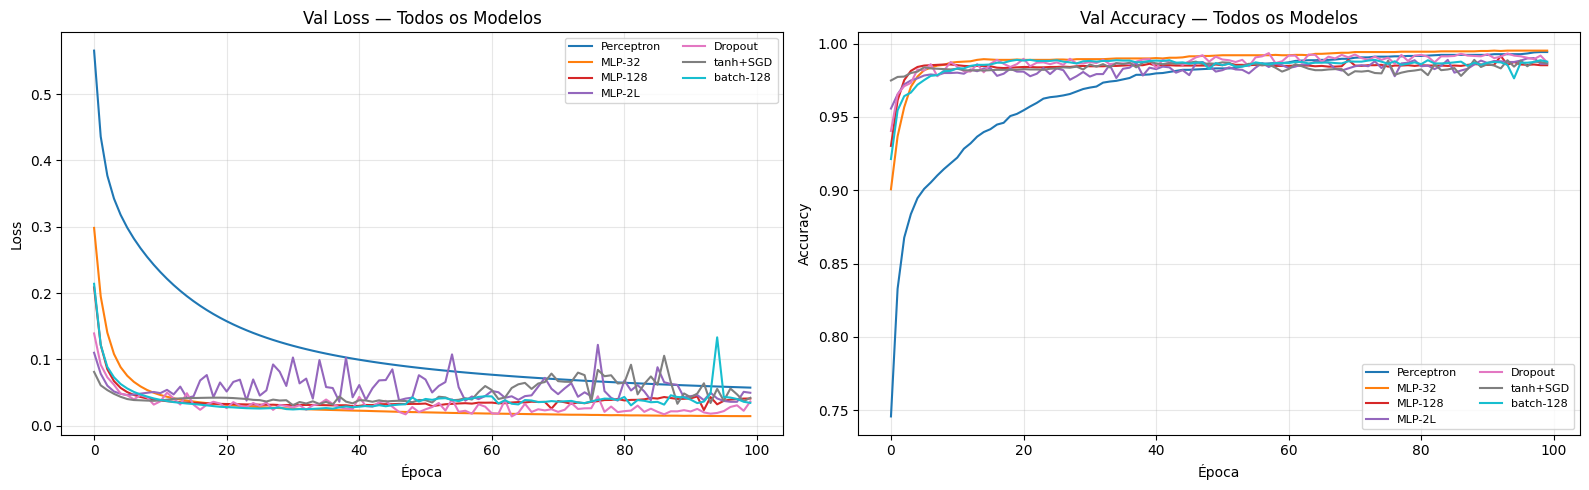

In [31]:
# Curvas de validação de todos os modelos sobrepostas
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

historicos  = [hist1, hist2, hist3, hist4, hist5, hist6, hist7]
nomes_curta = ['Perceptron', 'MLP-32', 'MLP-128', 'MLP-2L', 'Dropout', 'tanh+SGD', 'batch-128']
palette     = plt.cm.tab10(np.linspace(0, 0.9, 7))

for hist, nome, cor in zip(historicos, nomes_curta, palette):
    axes[0].plot(hist.history['val_loss'],     label=nome, color=cor, linewidth=1.5)
    axes[1].plot(hist.history['val_accuracy'], label=nome, color=cor, linewidth=1.5)

for ax, titulo, ylabel in zip(axes,
                               ['Val Loss — Todos os Modelos', 'Val Accuracy — Todos os Modelos'],
                               ['Loss', 'Accuracy']):
    ax.set_title(titulo, fontsize=12)
    ax.set_xlabel('Época')
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8, ncol=2)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [32]:
# Análise de overfitting: gap entre train e val loss na última época
print('=== Gap Train x Val Loss (última época) ===')
print(f'{"Modelo":<30} {"Train Loss":>12} {"Val Loss":>12} {"Gap":>10} {"Overfitting?":>14}')
print('-' * 80)
nomes_modelo = ['Perceptron Puro', 'MLP 32', 'MLP 128', 'MLP 2L (ref)', 'Dropout', 'tanh+SGD', 'batch-128']
for hist, nome in zip(historicos, nomes_modelo):
    tl = hist.history['loss'][-1]
    vl = hist.history['val_loss'][-1]
    gap = vl - tl
    flag = '⚠️  SIM' if gap > 0.05 else '✅  NÃO'
    print(f'{nome:<30} {tl:>12.4f} {vl:>12.4f} {gap:>10.4f} {flag:>14}')

=== Gap Train x Val Loss (última época) ===
Modelo                           Train Loss     Val Loss        Gap   Overfitting?
--------------------------------------------------------------------------------
Perceptron Puro                      0.0611       0.0576    -0.0035         ✅  NÃO
MLP 32                               0.0084       0.0146     0.0062         ✅  NÃO
MLP 128                              0.0029       0.0412     0.0382         ✅  NÃO
MLP 2L (ref)                         0.0071       0.0498     0.0427         ✅  NÃO
Dropout                              0.0144       0.0367     0.0223         ✅  NÃO
tanh+SGD                             0.0084       0.0422     0.0338         ✅  NÃO
batch-128                            0.0011       0.0346     0.0335         ✅  NÃO


---
## 8. Análise Crítica e Conclusões

### 8.1 Comportamento do Aprendizado

**Modelo 1 — Perceptron Puro (99.42% | val_loss 0.0576):**
Resultado surpreendente: o classificador linear ficou em 2º lugar. O train_loss (0.0611) foi **maior** que o val_loss (0.0576) — padrão de underfitting leve, onde o modelo não conseguiu ajustar completamente nem o treino. Isso confirma que a fronteira linear é insuficiente para capturar toda a estrutura dos dados, mas o RUL com alta correlação com o target faz com que mesmo uma separação linear seja bastante eficaz após a normalização.

**Modelo 2 — MLP 32 neurônios (99.52% | val_loss 0.0146) — melhor modelo:**
Com apenas 931 parâmetros treináveis, este foi o modelo mais eficiente. O menor val_loss (0.0146) e o menor gap treino/validação (0.0062) entre os MLPs indicam excelente generalização. A não-linearidade do ReLU foi suficiente para superar o Perceptron sem introduzir capacidade excessiva.

**Modelo 3 — MLP 128 neurônios (98.52% | val_loss 0.0412) — pior modelo:**
Aumentar os neurônios de 32 para 128 **piorou** tanto accuracy quanto val_loss. O train_loss despencou para 0.0029, mas o val_loss subiu para 0.0412 — gap de 0.0382, o maior entre os modelos de 1 camada. A rede com mais capacidade memorizou padrões do treino que não generalizam.

**Modelo 4 — MLP 2 Camadas 128→64 (98.62% | val_loss 0.0498):**
A maior profundidade não trouxe benefício — val_loss foi o mais alto de todos os modelos (0.0498) e gap de 0.0427. A segunda camada adicionou complexidade sem adicionar capacidade de generalização. Fica claro que o dataset não exige hierarquia profunda de representações.

**Modelo 5 — MLP com Dropout (98.72% | val_loss 0.0367 | recall Falha = 0.9980):**
O Dropout reduziu o val_loss de 0.0498 (modelo 4) para 0.0367 e o gap de 0.0427 para 0.0223, comprovando sua eficácia como regularizador. O train_loss (0.0144) ficou abaixo do val_loss (0.0367), comportamento normal. O destaque principal: **maior recall para Falha Crítica (0.9980)** — o modelo mais seguro operacionalmente, mesmo não sendo o de maior accuracy.

**Modelo 6 — MLP tanh + SGD (98.64% | recall Falha = 0.9912 | recall Normal = 0.9871):**
Pior perfil de recall entre todos os modelos. O SGD com momentum sem taxa adaptativa convergiu para uma solução menos balanceada entre classes. Accuracy competitiva, mas o desequilíbrio nos recalls — especialmente na classe Falha Crítica — torna este modelo inadequado para uso em sistemas de monitoramento real.

**Modelo 7 — MLP batch=128 (98.76% | train_loss 0.0011 | recall Falha = 0.9902):**
O train_loss mais baixo do experimento (0.0011) confirma que gradientes mais precisos ajustam melhor o treino. Porém, o recall para Falha foi o mais baixo entre os modelos Adam (0.9902), mostrando que batches grandes sacrificam sensibilidade na classe crítica em troca de maior ajuste ao treino.

### 8.2 Padrão Geral Observado: Simplicidade Vence

O resultado mais importante do experimento é que **modelos mais simples generalizaram melhor**. O ranking final vai na direção oposta à intuição de "mais parâmetros = melhor":

| Parâmetros | Modelo | Accuracy |
|-----------|--------|---------|
| 78 | Perceptron Puro | 99.42% |
| **931** | **MLP 32** | **99.52%** |
| 3.715 | MLP 128 | 98.52% |
| 11.779 | MLP 2L / Dropout / batch-128 | 98.62–98.76% |

Isso ocorre porque após a normalização com StandardScaler o dataset torna-se altamente separável, com o RUL como feature dominante. Modelos com mais parâmetros têm maior tendência a ajustar ruído específico do treino.

### 8.3 Impacto da Normalização

O StandardScaler foi determinante. As features têm escalas radicalmente diferentes (de 0.0004 a 518.67), e sem normalização o gradiente seria dominado pelas features de maior magnitude. A padronização para média ≈ 0 e desvio padrão ≈ 0.72 equilibrou a contribuição de todas as features, tornando o problema quasi-linearmente separável e permitindo que até o Perceptron Puro obtivesse 99.42%.

### 8.4 Qual Modelo Usar em Produção?

Para sistemas espaciais reais, a métrica mais crítica é o **recall da Falha Crítica** — um falso negativo pode significar perda do satélite. Com esse critério:

| Modelo | Accuracy | Recall Falha | Recomendação |
|--------|----------|-------------|-------------|
| MLP 32 | 99.52% | 0.9971 | Melhor equilíbrio geral |
| **MLP Dropout** | **98.72%** | **0.9980** | **Mais seguro para produção** |
| tanh+SGD | 98.64% | 0.9912 | Não recomendado |
| batch=128 | 98.76% | 0.9902 | Não recomendado |

In [33]:
# Análise de recall da classe crítica (Falha = 2) em todos os modelos
from sklearn.metrics import recall_score

modelos_lista = [modelo1, modelo2, modelo3, modelo4, modelo5, modelo6, modelo7]

print(f'{"Modelo":<30} {"Acc (%)":>8} {"Recall Falha":>14} {"Recall Normal":>15}')
print('-' * 72)
for modelo, nome, r in zip(modelos_lista, nomes_modelo, resultados):
    y_pred = np.argmax(modelo.predict(X_test, verbose=0), axis=1)
    recall_falha  = recall_score(y_test, y_pred, labels=[2], average=None)[0]
    recall_normal = recall_score(y_test, y_pred, labels=[0], average=None)[0]
    print(f'{nome:<30} {r["accuracy"]:>8.2f} {recall_falha:>14.4f} {recall_normal:>15.4f}')

Modelo                          Acc (%)   Recall Falha   Recall Normal
------------------------------------------------------------------------
Perceptron Puro                   99.42         0.9931          0.9982
MLP 32                            99.52         0.9971          0.9965
MLP 128                           98.52         0.9931          0.9824
MLP 2L (ref)                      98.62         0.9922          0.9959
Dropout                           98.72         0.9980          0.9965
tanh+SGD                          98.64         0.9912          0.9871
batch-128                         98.76         0.9902          0.9912


In [34]:
# Identificar e destacar o melhor modelo geral
melhor = df_resultados.iloc[0]
print(f'\n🏆 MELHOR MODELO POR ACCURACY: {melhor["titulo"]}')
print(f'   Accuracy no Teste: {melhor["accuracy"]:.2f}%')
print(f'   Loss no Teste:     {melhor["loss"]:.4f}')
print()
print('Resumo da evolução de accuracy:')
for r in resultados:
    print(f'  {r["titulo"]:<30}  →  {r["accuracy"]:>6.2f}%')


🏆 MELHOR MODELO POR ACCURACY: MLP 1 Camada (32 neurônios)
   Accuracy no Teste: 99.52%
   Loss no Teste:     0.0146

Resumo da evolução de accuracy:
  Perceptron Puro                 →   99.42%
  MLP 1 Camada (32 neurônios)     →   99.52%
  MLP 1 Camada (128 neurônios)    →   98.52%
  MLP 2 Camadas (128→64)          →   98.62%
  MLP com Dropout (p=0.3)         →   98.72%
  MLP tanh + SGD (momentum=0.9)   →   98.64%
  MLP 2 Camadas (batch=128)       →   98.76%


---
## 9. Conclusão Final

Este trabalho demonstrou o pipeline completo de desenvolvimento de modelos de redes neurais para classificação de estados operacionais de sistemas espaciais simulados, utilizando dados derivados do dataset C-MAPSS da NASA.

**Principais aprendizados confirmados pelos dados:**

1. **Normalização transforma o problema:** O StandardScaler tornou as classes quasi-linearmente separáveis, permitindo que até o Perceptron Puro atingisse 99.42%. Sem normalização, os resultados seriam dramaticamente piores.

2. **Simplicidade venceu a complexidade:** O melhor modelo foi o MLP com apenas 32 neurônios e 931 parâmetros (99.52%), superando redes com até 11.779 parâmetros. O ranking confirmou: mais neurônios e mais camadas pioraram a performance neste dataset.

3. **Mais parâmetros → mais overfitting:** O MLP-128 foi o pior (98.52%), com train_loss 0.0029 e val_loss 0.0412 — o maior gap entre os modelos de 1 camada. O MLP-2L teve val_loss 0.0498, o maior de todos.

4. **Dropout é o melhor regularizador aqui:** Reduziu o val_loss do modelo 2 camadas de 0.0498 para 0.0367 e produziu o maior recall para Falha Crítica (0.9980). Para uso operacional em sistemas espaciais, é o modelo recomendado.

5. **Adam foi superior ao SGD:** O SGD convergiu para a solução mais desequilibrada entre classes — piores recalls tanto para Falha (0.9912) quanto para Normal (0.9871), evidenciando que a falta de taxa adaptativa prejudicou o balanceamento.

6. **Batch size maior sacrifica recall crítico:** batch=128 obteve o menor train_loss (0.0011) mas o pior recall para Falha entre os modelos Adam (0.9902). Batches menores, com ruído estocástico no gradiente, produziram modelos mais sensíveis à classe minoritária.

7. **Accuracy isolada não é suficiente:** A diferença entre o melhor (99.52%) e o pior (98.52%) é de apenas 1 ponto percentual, mas a diferença em recall para Falha Crítica (0.9980 vs 0.9902) representa um risco operacional real em sistemas espaciais.

---
*Orbital Climate Intelligence Platform — Global Solution 2026.1 — FIAP DL-CNN*